In [1]:
import random
from engine import Value
from nn import MLP
from viz import draw_dot

random.seed(42)

## 1. Backprop through a single neuron
$o = \tanh(x_1 w_1 + x_2 w_2 + b)$

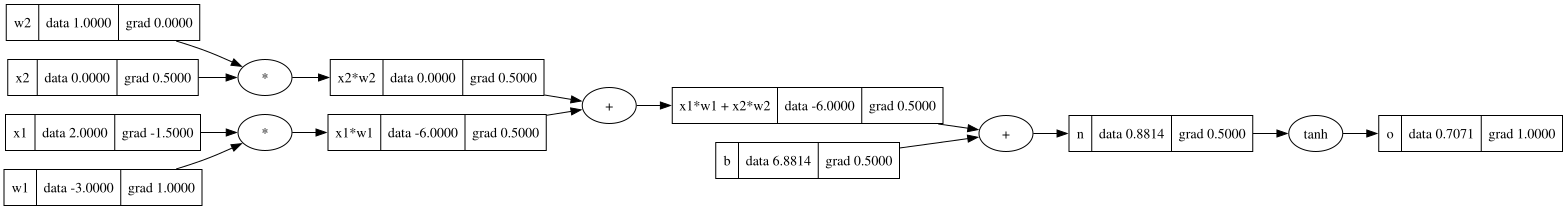

In [2]:
x1 = Value(2.0, label='x1'); x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1'); w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.backward()
draw_dot(o)

## 2. Training an MLP
A 3 → 4 → 4 → 1 network on a tiny toy dataset, trained with gradient descent on squared-error loss.

In [3]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  # targets

model = MLP(3, [4, 4, 1])

In [4]:
for k in range(50):
    # forward pass
    ypred = [model(x) for x in xs]
    loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
    # backward pass
    for p in model.parameters():
        p.grad = 0.0
    loss.backward()

    #update
    for p in model.parameters():
        p.data += -0.01 * p.grad
                
    print(k, loss.data)

0 5.230517512042234
1 4.561050613053606
2 3.920921244201552
3 3.38976189493446
4 2.982053787994396
5 2.67028216785508
6 2.4154175593497116
7 2.1873515353941833
8 1.9732871952894058
9 1.7742972754767687
10 1.5953557525758697
11 1.4387396877362955
12 1.303622529443269
13 1.18762262418578
14 1.0879156326792871
15 1.0017947259573161
16 0.9269029442790254
17 0.8612882145868146
18 0.8033742408725233
19 0.7519012046913895
20 0.705863163572887
21 0.6644530554774059
22 0.6270181746939707
23 0.593025555210131
24 0.5620355730877615
25 0.5336819602969685
26 0.5076566680287582
27 0.48369834506015474
28 0.46158349778402774
29 0.44111964183122226
30 0.42213994035171676
31 0.4044989605656224
32 0.38806927930407775
33 0.37273873969570687
34 0.35840821257569766
35 0.34498975330089293
36 0.3324050715673347
37 0.3205842514819252
38 0.3094646736123989
39 0.2989901014926953
40 0.2891099031266987
41 0.27977838414311895
42 0.27095421392823893
43 0.26259992967366474
44 0.2546815060916377
45 0.24716798076601532

In [5]:
[round(y.data, 3) for y in ypred]

[0.737, -0.848, -0.699, 0.805]

In [6]:
for k in range(50):
    # forward pass
    ypred = [model(x) for x in xs]
    loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
    # backward pass
    for p in model.parameters():
        p.grad = 0.0
    loss.backward()

    #update
    for p in model.parameters():
        p.data += -0.01 * p.grad
                
    print(k, loss.data)

[round(y.data, 3) for y in ypred]

0 0.2147665098890665
1 0.20916709901720748
2 0.20381857008244642
3 0.19870546425066402
4 0.19381351414011633
5 0.1891295347368839
6 0.18464132581040263
7 0.18033758445989526
8 0.1762078266044807
9 0.17224231638487456
10 0.16843200257728314
11 0.16476846123391561
12 0.16124384386245166
13 0.15785083054125337
14 0.15458258744012962
15 0.15143272827974535
16 0.14839527931774224
17 0.14546464749749113
18 0.14263559143714172
19 0.13990319497311549
20 0.13726284300414388
21 0.1347101994099726
22 0.1322411868434918
23 0.1298519682167296
24 0.12753892972026726
25 0.12529866523251748
26 0.12312796199024237
27 0.12102378740491794
28 0.11898327692128548
29 0.11700372282485826
30 0.115082563914426
31 0.11321737596386328
32 0.11140586290491256
33 0.10964584866920146
34 0.1079352696336331
35 0.10627216761855973
36 0.10465468339287554
37 0.10308105064439739
38 0.10154959037771825
39 0.10005870570513523
40 0.09860687699934718
41 0.09719265737938697
42 0.09581466850377363
43 0.09447159664712476
44 0.09

[0.837, -0.904, -0.812, 0.873]

## Checking with PyTorch

In [7]:
import torch

t = lambda v: torch.tensor([v], dtype=torch.double, requires_grad=True)
tx1, tx2, tw1, tw2, tb = t(2.0), t(0.0), t(-3.0), t(1.0), t(6.8813735870195432)
to = torch.tanh(tx1*tw1 + tx2*tw2 + tb)
to.backward()

for name, mine, theirs in [('x1', x1, tx1), ('w1', w1, tw1), ('x2', x2, tx2), ('w2', w2, tw2), ('b', b, tb)]:
    print(f"{name}: micrograd {mine.grad:+.4f}   pytorch {theirs.grad.item():+.4f}")

x1: micrograd -1.5000   pytorch -1.5000
w1: micrograd +1.0000   pytorch +1.0000
x2: micrograd +0.5000   pytorch +0.5000
w2: micrograd +0.0000   pytorch +0.0000
b: micrograd +0.5000   pytorch +0.5000


## 3. Classifying make_moons
Two interlocking half-circles: no straight line can separate them, so a linear model fails. The nonlinearity in the MLP lets it learn a curved decision boundary.

Text(0.5, 1.0, 'make_moons')

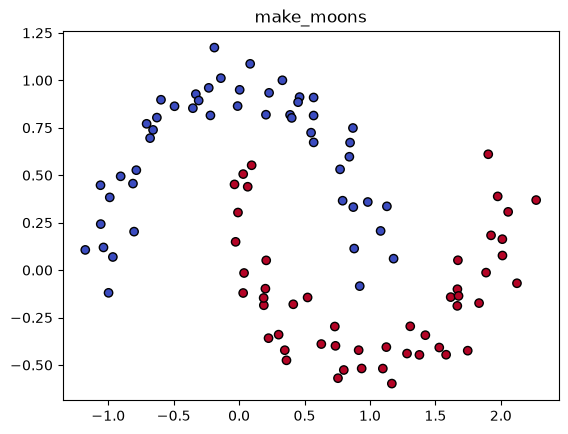

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=100, noise=0.1, random_state=42)
y = y*2 - 1   # labels 0/1 → -1/+1 to match tanh's output range

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title('make_moons')

In [18]:
moons_model = MLP(2, [16, 16, 1])  
print(len(moons_model.parameters()), "parameters")

337 parameters


In [19]:
def evaluate():
    scores = [moons_model(list(map(Value, xi))) for xi in X]
    loss = sum((s - yi)**2 for s, yi in zip(scores, y)) / len(y)    # mean squared error
    acc = sum((s.data > 0) == (yi > 0) for s, yi in zip(scores, y)) / len(y)
    return loss, acc

In [20]:
for k in range(50):
    loss, acc = evaluate()

    for p in moons_model.parameters():
        p.grad = 0.0
    loss.backward()

    lr = 0.5 - 0.4 * k / 100   # learning rate decays from 0.5 → 0.1
    for p in moons_model.parameters():
        p.data -= lr * p.grad

    if k % 10 == 0:
        print(f"step {k:3d}  loss {loss.data:.4f}  accuracy {acc*100:.0f}%")

step   0  loss 1.1799  accuracy 53%
step  10  loss 0.1680  accuracy 95%
step  20  loss 0.1002  accuracy 96%
step  30  loss 0.0676  accuracy 98%
step  40  loss 0.0311  accuracy 100%


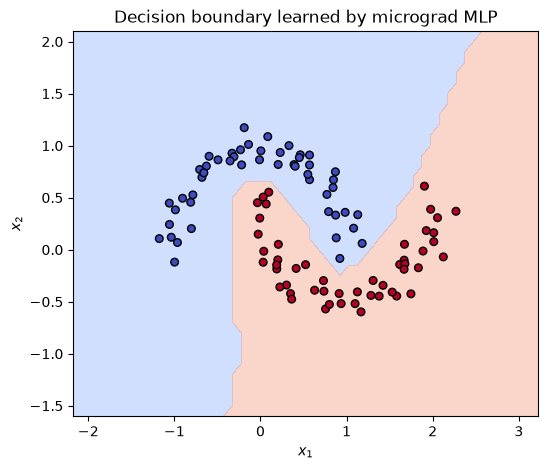

In [22]:
h = 0.1
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid = np.c_[xx.ravel(), yy.ravel()]

Z = np.array([moons_model(list(map(Value, p))).data > 0 for p in grid]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, Z, cmap='coolwarm', alpha=0.4)
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=30, edgecolors='k')
ax.set_title('Decision boundary learned by micrograd MLP')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
fig.savefig('../assets/micrograd_decision_boundary.png', dpi=150, bbox_inches='tight')